In [1]:
!pip install pandas scikit-learn joblib


In [2]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

import joblib


In [3]:
# Read the dataset
df = pd.read_csv("data.csv")

# Show first 5 rows
df.head()


,id,target,comment_text,severe_toxicity,obscene,identity_attack,insult,threat,asian,atheist,...,article_id,rating,funny,wow,sad,likes,disagree,sexual_explicit,identity_annotator_count,toxicity_annotator_count
0,59856,0.893617,haha you guys are a bunch of losers.,0.021277,0.000000,0.021277,0.872340,0.0000,0.0,0.0,...,2006,rejected,0,0,0,1,0,0.000000,4,47
1,239607,0.912500,Yet call out all Muslims for the acts of a few...,0.050000,0.237500,0.612500,0.887500,0.1125,0.0,0.0,...,26670,approved,0,0,0,1,0,0.000000,4,80
2,239612,0.830769,This bitch is nuts. Who would read a book by a...,0.107692,0.661538,0.338462,0.830769,0.0000,0.0,0.0,...,26674,rejected,0,0,0,0,0,0.061538,4,65
3,240311,0.968750,You're an idiot.,0.031250,0.062500,0.000000,0.968750,0.0000,NaN,NaN,...,32846,rejected,0,0,0,0,0,0.000000,0,32
4,240329,0.900000,Who cares!? Stark trek and Star Wars fans are ...,0.100000,0.200000,0.000000,0.900000,0.0000,NaN,NaN,...,32846,rejected,0,0,0,0,0,0.300000,0,10


In [4]:
# Basic dataset stats before any processing
print("📊 Basic dataset info\n")

print("Shape (rows, columns):", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nMissing values per column:")
print(df.isna().sum())

print("\nTarget column statistics:")
print(df["target"].describe())


📊 Basic dataset info

Shape (rows, columns): (90902, 45)

Columns:
['id', 'target', 'comment_text', 'severe_toxicity', 'obscene', 'identity_attack', 'insult', 'threat', 'asian', 'atheist', 'bisexual', 'black', 'buddhist', 'christian', 'female', 'heterosexual', 'hindu', 'homosexual_gay_or_lesbian', 'intellectual_or_learning_disability', 'jewish', 'latino', 'male', 'muslim', 'other_disability', 'other_gender', 'other_race_or_ethnicity', 'other_religion', 'other_sexual_orientation', 'physical_disability', 'psychiatric_or_mental_illness', 'transgender', 'white', 'created_date', 'publication_id', 'parent_id', 'article_id', 'rating', 'funny', 'wow', 'sad', 'likes', 'disagree', 'sexual_explicit', 'identity_annotator_count', 'toxicity_annotator_count']

Missing values per column:
id                                         0
target                                     0
comment_text                               0
severe_toxicity                            0
obscene                              

In [5]:
# We only need comment_text and target for now
df = df[["comment_text", "target"]].copy()

# Drop rows with missing values in these columns
df = df.dropna(subset=["comment_text", "target"])

# Create binary label:
# 1 = toxic (target >= 0.5)
# 0 = non-toxic (target < 0.5)
df["label"] = (df["target"] >= 0.5).astype(int)

# Check label distribution
print(df["label"].value_counts())
print(df["label"].value_counts(normalize=True))

# Just to see a sample
df.head()


label
1    45451
0    45451
Name: count, dtype: int64
label
1    0.5
0    0.5
Name: proportion, dtype: float64


,comment_text,target,label
0,haha you guys are a bunch of losers.,0.893617,1
1,Yet call out all Muslims for the acts of a few...,0.912500,1
2,This bitch is nuts. Who would read a book by a...,0.830769,1
3,You're an idiot.,0.968750,1
4,Who cares!? Stark trek and Star Wars fans are ...,0.900000,1


In [6]:
print("📊 Label distribution (after binarization)\n")

label_counts = df["label"].value_counts()
label_perc = df["label"].value_counts(normalize=True) * 100

print("Counts:")
print(label_counts)
print("\nPercentages:")
print(label_perc.round(2))

# Comment length stats
df["comment_length"] = df["comment_text"].astype(str).str.len()

print("\n📏 Comment length statistics:")
print(df["comment_length"].describe())


📊 Label distribution (after binarization)

Counts:
label
1    45451
0    45451
Name: count, dtype: int64

Percentages:
label
1    50.0
0    50.0
Name: proportion, dtype: float64

📏 Comment length statistics:
count    90902.000000
mean       253.051869
std        242.056543
min          1.000000
25%         81.000000
50%        167.000000
75%        338.000000
max       1535.000000
Name: comment_length, dtype: float64


C:\Users\alshh\AppData\Local\Temp\ipykernel_28780\3541103322.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=df["label"], palette="viridis")


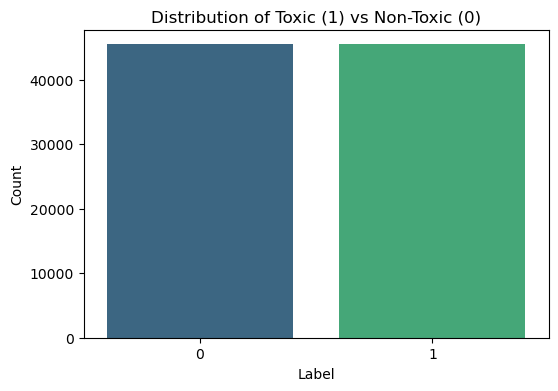

In [7]:


import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))
sns.countplot(x=df["label"], palette="viridis")
plt.title("Distribution of Toxic (1) vs Non-Toxic (0)")
plt.xlabel("Label")
plt.ylabel("Count")
plt.show()



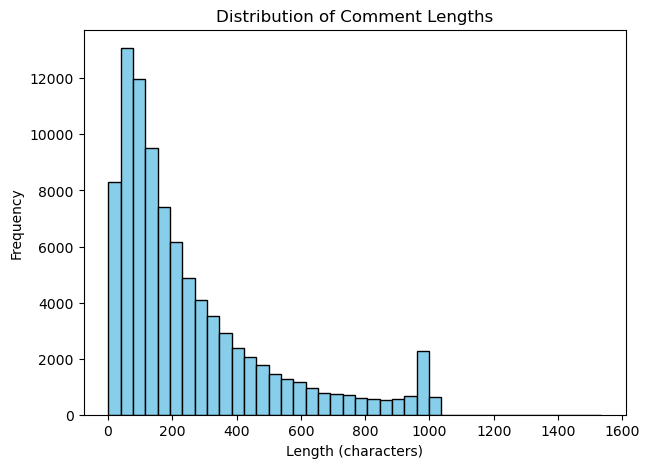

In [8]:
plt.figure(figsize=(7,5))
plt.hist(df["comment_length"], bins=40, color="skyblue", edgecolor="black")
plt.title("Distribution of Comment Lengths")
plt.xlabel("Length (characters)")
plt.ylabel("Frequency")
plt.show()


In [9]:
print("\n🟢 Example NON-Toxic comments:")
print(df[df["label"] == 0]["comment_text"].head(5))

print("\n🔴 Example TOXIC comments:")
print(df[df["label"] == 1]["comment_text"].head(5))



🟢 Example NON-Toxic comments:
45451    Great letter Declan!  I totally agree.  It' sa...
45452    The state of Alaska tried that years ago. Brou...
45453    And what mess it this? Are we adding in state ...
45454    It is unfortunate that the silvers decided to ...
45455    It's just going to take time and reps, especia...
Name: comment_text, dtype: object

🔴 Example TOXIC comments:
0                 haha you guys are a bunch of losers.
1    Yet call out all Muslims for the acts of a few...
2    This bitch is nuts. Who would read a book by a...
3                                     You're an idiot.
4    Who cares!? Stark trek and Star Wars fans are ...
Name: comment_text, dtype: object


In [10]:
# Features (text) and labels (0/1)
X = df["comment_text"]
y = df["label"]

print("Total samples:", len(X))


Total samples: 90902


In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,    # 20% test, 80% train
    random_state=42,
    stratify=y         # keep same class balance in train/test
)

print("Train size:", len(X_train))
print("Test size:", len(X_test))


Train size: 72721
Test size: 18181


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report

#Algorithm 1: Logistic Regression
lr_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        stop_words="english",
        max_features=20000,
        ngram_range=(1, 2)
    )),
    ("clf", LogisticRegression(max_iter=300))
])

print("Training Logistic Regression...")
lr_model.fit(X_train, y_train)

lr_pred = lr_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, lr_pred))
print("F1-score:", f1_score(y_test, lr_pred))
print("\nClassification report:")
print(classification_report(y_test, lr_pred))


Training Logistic Regression...
Accuracy: 0.9180463120840437
F1-score: 0.9141606175826709

Classification report:
              precision    recall  f1-score   support

           0       0.88      0.96      0.92      9091
           1       0.96      0.87      0.91      9090

    accuracy                           0.92     18181
   macro avg       0.92      0.92      0.92     18181
weighted avg       0.92      0.92      0.92     18181



In [ ]:
from sklearn.svm import LinearSVC
#Algorithm 2: Linear SVM
svm_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        stop_words="english",
        max_features=20000,
        ngram_range=(1, 2)
    )),
    ("clf", LinearSVC())
])

print("Training Linear SVM...")
svm_model.fit(X_train, y_train)

svm_pred = svm_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, svm_pred))
print("F1-score:", f1_score(y_test, svm_pred))
print("\nClassification report:")
print(classification_report(y_test, svm_pred))


Training Linear SVM...
Accuracy: 0.9298168417578792
F1-score: 0.9281207751239297

Classification report:
              precision    recall  f1-score   support

           0       0.91      0.95      0.93      9091
           1       0.95      0.91      0.93      9090

    accuracy                           0.93     18181
   macro avg       0.93      0.93      0.93     18181
weighted avg       0.93      0.93      0.93     18181



In [ ]:
from sklearn.ensemble import RandomForestClassifier
#Algorithm 3: Random Forest
rf_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        stop_words="english",
        max_features=15000,
        ngram_range=(1, 2)
    )),
    ("clf", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

print("Training Random Forest...")
rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, rf_pred))
print("F1-score:", f1_score(y_test, rf_pred))
print("\nClassification report:")
print(classification_report(y_test, rf_pred))


Training Random Forest...
Accuracy: 0.9196413838622738
F1-score: 0.9181925079791702

Classification report:
              precision    recall  f1-score   support

           0       0.91      0.94      0.92      9091
           1       0.93      0.90      0.92      9090

    accuracy                           0.92     18181
   macro avg       0.92      0.92      0.92     18181
weighted avg       0.92      0.92      0.92     18181



In [ ]:
import pandas as pd
#Comparison Between the Three Algorithms
results_df = pd.DataFrame({
    "Model": ["Logistic Regression", "Linear SVM", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, lr_pred),
        accuracy_score(y_test, svm_pred),
        accuracy_score(y_test, rf_pred)
    ],
    "F1-score": [
        f1_score(y_test, lr_pred),
        f1_score(y_test, svm_pred),
        f1_score(y_test, rf_pred)
    ]
})

results_df


,Model,Accuracy,F1-score
0,Logistic Regression,0.918046,0.914161
1,Linear SVM,0.929817,0.928121
2,Random Forest,0.919641,0.918193


In [17]:
model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        stop_words="english",
        max_features=20000,
        ngram_range=(1, 2)   # unigrams + bigrams
    )),
    ("clf", LogisticRegression(
        max_iter=300,
        n_jobs=-1
    ))
])

model


Pipeline(steps=[('tfidf',
                 TfidfVectorizer(max_features=20000, ngram_range=(1, 2),
                                 stop_words='english')),
                ('clf', LogisticRegression(max_iter=300, n_jobs=-1))])

In [18]:
print("Training the model...")
model.fit(X_train, y_train)
print("Done.")


Training the model...
Done.


In [19]:
# Predict on the test set
y_pred = model.predict(X_test)

# Accuracy
acc = accuracy_score(y_test, y_pred)
print("Accuracy on test set: {:.4f}".format(acc))

# Detailed report
print("\nClassification report:")
print(classification_report(y_test, y_pred))


Accuracy on test set: 0.9180

Classification report:
              precision    recall  f1-score   support

           0       0.88      0.96      0.92      9091
           1       0.96      0.87      0.91      9090

    accuracy                           0.92     18181
   macro avg       0.92      0.92      0.92     18181
weighted avg       0.92      0.92      0.92     18181



In [20]:
MODEL_PATH = "toxicity_model.pkl"
joblib.dump(model, MODEL_PATH)
print(f"Model saved to {MODEL_PATH}")


Model saved to toxicity_model.pkl


In [21]:
test_comments = [
    "I hate you, you are so stupid",
    "Thank you for your help, I really appreciate it",
    "You are an idiot",
    "Have a nice day!"
]

preds = model.predict(test_comments)

for text, p in zip(test_comments, preds):
    label = "Toxic" if p == 1 else "Non-toxic"
    print(f"{label}  --->  {text}")


Toxic  --->  I hate you, you are so stupid
Non-toxic  --->  Thank you for your help, I really appreciate it
Toxic  --->  You are an idiot
Non-toxic  --->  Have a nice day!
